# Statistical testing

This notebook tests the 11 numeric variables in `hcv_median_imputed.csv` (608 patients) for normality and for differences between the four categories. It follows the same steps as the COM725 analysis: normality tests, Q-Q plots, Kruskal-Wallis, then a quantile transformation followed by one-way ANOVA and a correlation heatmap. Bonferroni-adjusted p-values are shown next to the raw ones.

Outliers are not removed because the extreme values belong to the sick patients (see `cleaning.ipynb`).

## Configuration and data

Paths, the random seed, the significance level and the class order are set once here.

In [1]:
# standard library, then third-party imports
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from scipy import stats
from sklearn.preprocessing import QuantileTransformer

# settings used throughout: file name, random seed, significance level,
# the target column and the fixed order of the four categories
DATA_PATH = Path("hcv_median_imputed.csv")
SEED = 42
ALPHA = 0.05
TARGET = "Category"
CLASS_ORDER = ["Healthy", "Hepatitis", "Fibrosis", "Cirrhosis"]

# the 11 measurements we test. cat_num is a label code, so it is excluded
NUMERIC_COLUMNS = [
    "Age", "ALB", "ALP", "ALT", "AST", "BIL",
    "CHE", "CHOL", "CREA", "GGT", "PROT",
]
PLOTS_PER_ROW = 4

In [2]:
# read the cleaned data and fix the category order so that groups always
# appear as Healthy, Hepatitis, Fibrosis, Cirrhosis
df = pd.read_csv(DATA_PATH)
df[TARGET] = pd.Categorical(df[TARGET], categories=CLASS_ORDER)

# check the size and how many patients are in each category
print(df.shape)
df[TARGET].value_counts()

(608, 14)


Category
Healthy      533
Cirrhosis     30
Hepatitis     24
Fibrosis      21
Name: count, dtype: int64

## Normality and data distribution analysis

Each variable is tested with Shapiro-Wilk and D'Agostino-Pearson. The p-values are Bonferroni adjusted for 22 tests (two tests on 11 variables). A variable is called normal only if neither adjusted p-value is below 0.05.

In [3]:
# collect one row of results per variable
normality_rows = []
for column in NUMERIC_COLUMNS:
    values = df[column]

    # Shapiro-Wilk and D'Agostino-Pearson both test the null hypothesis
    # that the values come from a normal distribution
    shapiro_w, shapiro_p = stats.shapiro(values)
    k2, k2_p = stats.normaltest(values)

    # descriptive statistics help to explain why a test rejects normality
    normality_rows.append({
        "Variable": column,
        "Mean": values.mean(),
        "Median": values.median(),
        "Std": values.std(),
        "Skewness": stats.skew(values),
        "Kurtosis": stats.kurtosis(values),
        "Shapiro W": shapiro_w,
        "Shapiro p": shapiro_p,
        "K2": k2,
        "K2 p": k2_p,
    })
normality_df = pd.DataFrame(normality_rows).set_index("Variable")

# Bonferroni: multiply each p-value by the number of tests in the family
# (11 variables x 2 tests = 22) and cap at 1, because a p-value cannot
# exceed 1. This guards against false positives from many tests
family_size = len(NUMERIC_COLUMNS) * 2
normality_df["Shapiro p (adj)"] = (
    normality_df["Shapiro p"] * family_size).clip(upper=1)
normality_df["K2 p (adj)"] = (
    normality_df["K2 p"] * family_size).clip(upper=1)

# A variable counts as normal only if neither adjusted test rejects it
normality_df["Normal"] = (
    (normality_df["Shapiro p (adj)"] >= ALPHA)
    & (normality_df["K2 p (adj)"] >= ALPHA)
)
normality_df.round(4)

,Mean,Median,Std,Skewness,Kurtosis,Shapiro W,Shapiro p,K2,K2 p,Shapiro p (adj),K2 p (adj),Normal
Variable,,,,,,,,,,,,
Age,47.2911,47.00,9.9927,0.2537,-0.4230,0.9840,0.0000,13.2406,0.0013,0.0001,0.0293,False
ALB,41.8191,42.00,5.4023,0.2924,6.1727,0.9429,0.0000,95.6194,0.0000,0.0000,0.0000,False
ALP,67.7671,66.00,24.8988,4.9428,63.1099,0.7658,0.0000,682.6496,0.0000,0.0000,0.0000,False
ALT,27.5938,23.00,21.2109,4.1690,30.1048,0.6812,0.0000,578.0350,0.0000,0.0000,0.0000,False
AST,34.3694,25.85,32.6224,5.1233,32.8477,0.4586,0.0000,654.1583,0.0000,0.0000,0.0000,False
BIL,11.4740,7.30,19.7706,8.3260,81.6672,0.3123,0.0000,901.0631,0.0000,0.0000,0.0000,False
CHE,8.2049,8.27,2.1684,-0.1550,1.3786,0.9795,0.0000,22.8756,0.0000,0.0000,0.0002,False
CHOL,5.3775,5.30,1.1102,0.4020,0.7714,0.9882,0.0001,24.9802,0.0000,0.0018,0.0001,False
CREA,81.5132,77.00,49.7207,15.3258,281.5685,0.2345,0.0000,1251.1555,0.0000,0.0000,0.0000,False


### Findings

None of the 11 variables follows a normal distribution. CREA is the most skewed (15.33), followed by BIL (8.33), GGT (6.09), AST (5.12) and ALP (4.94). For AST, BIL and GGT the mean is well above the median, which shows a long right tail.

## Q-Q plots

Points on the line mean the variable is normal. Points that bend away from the line show skew or heavy tails.

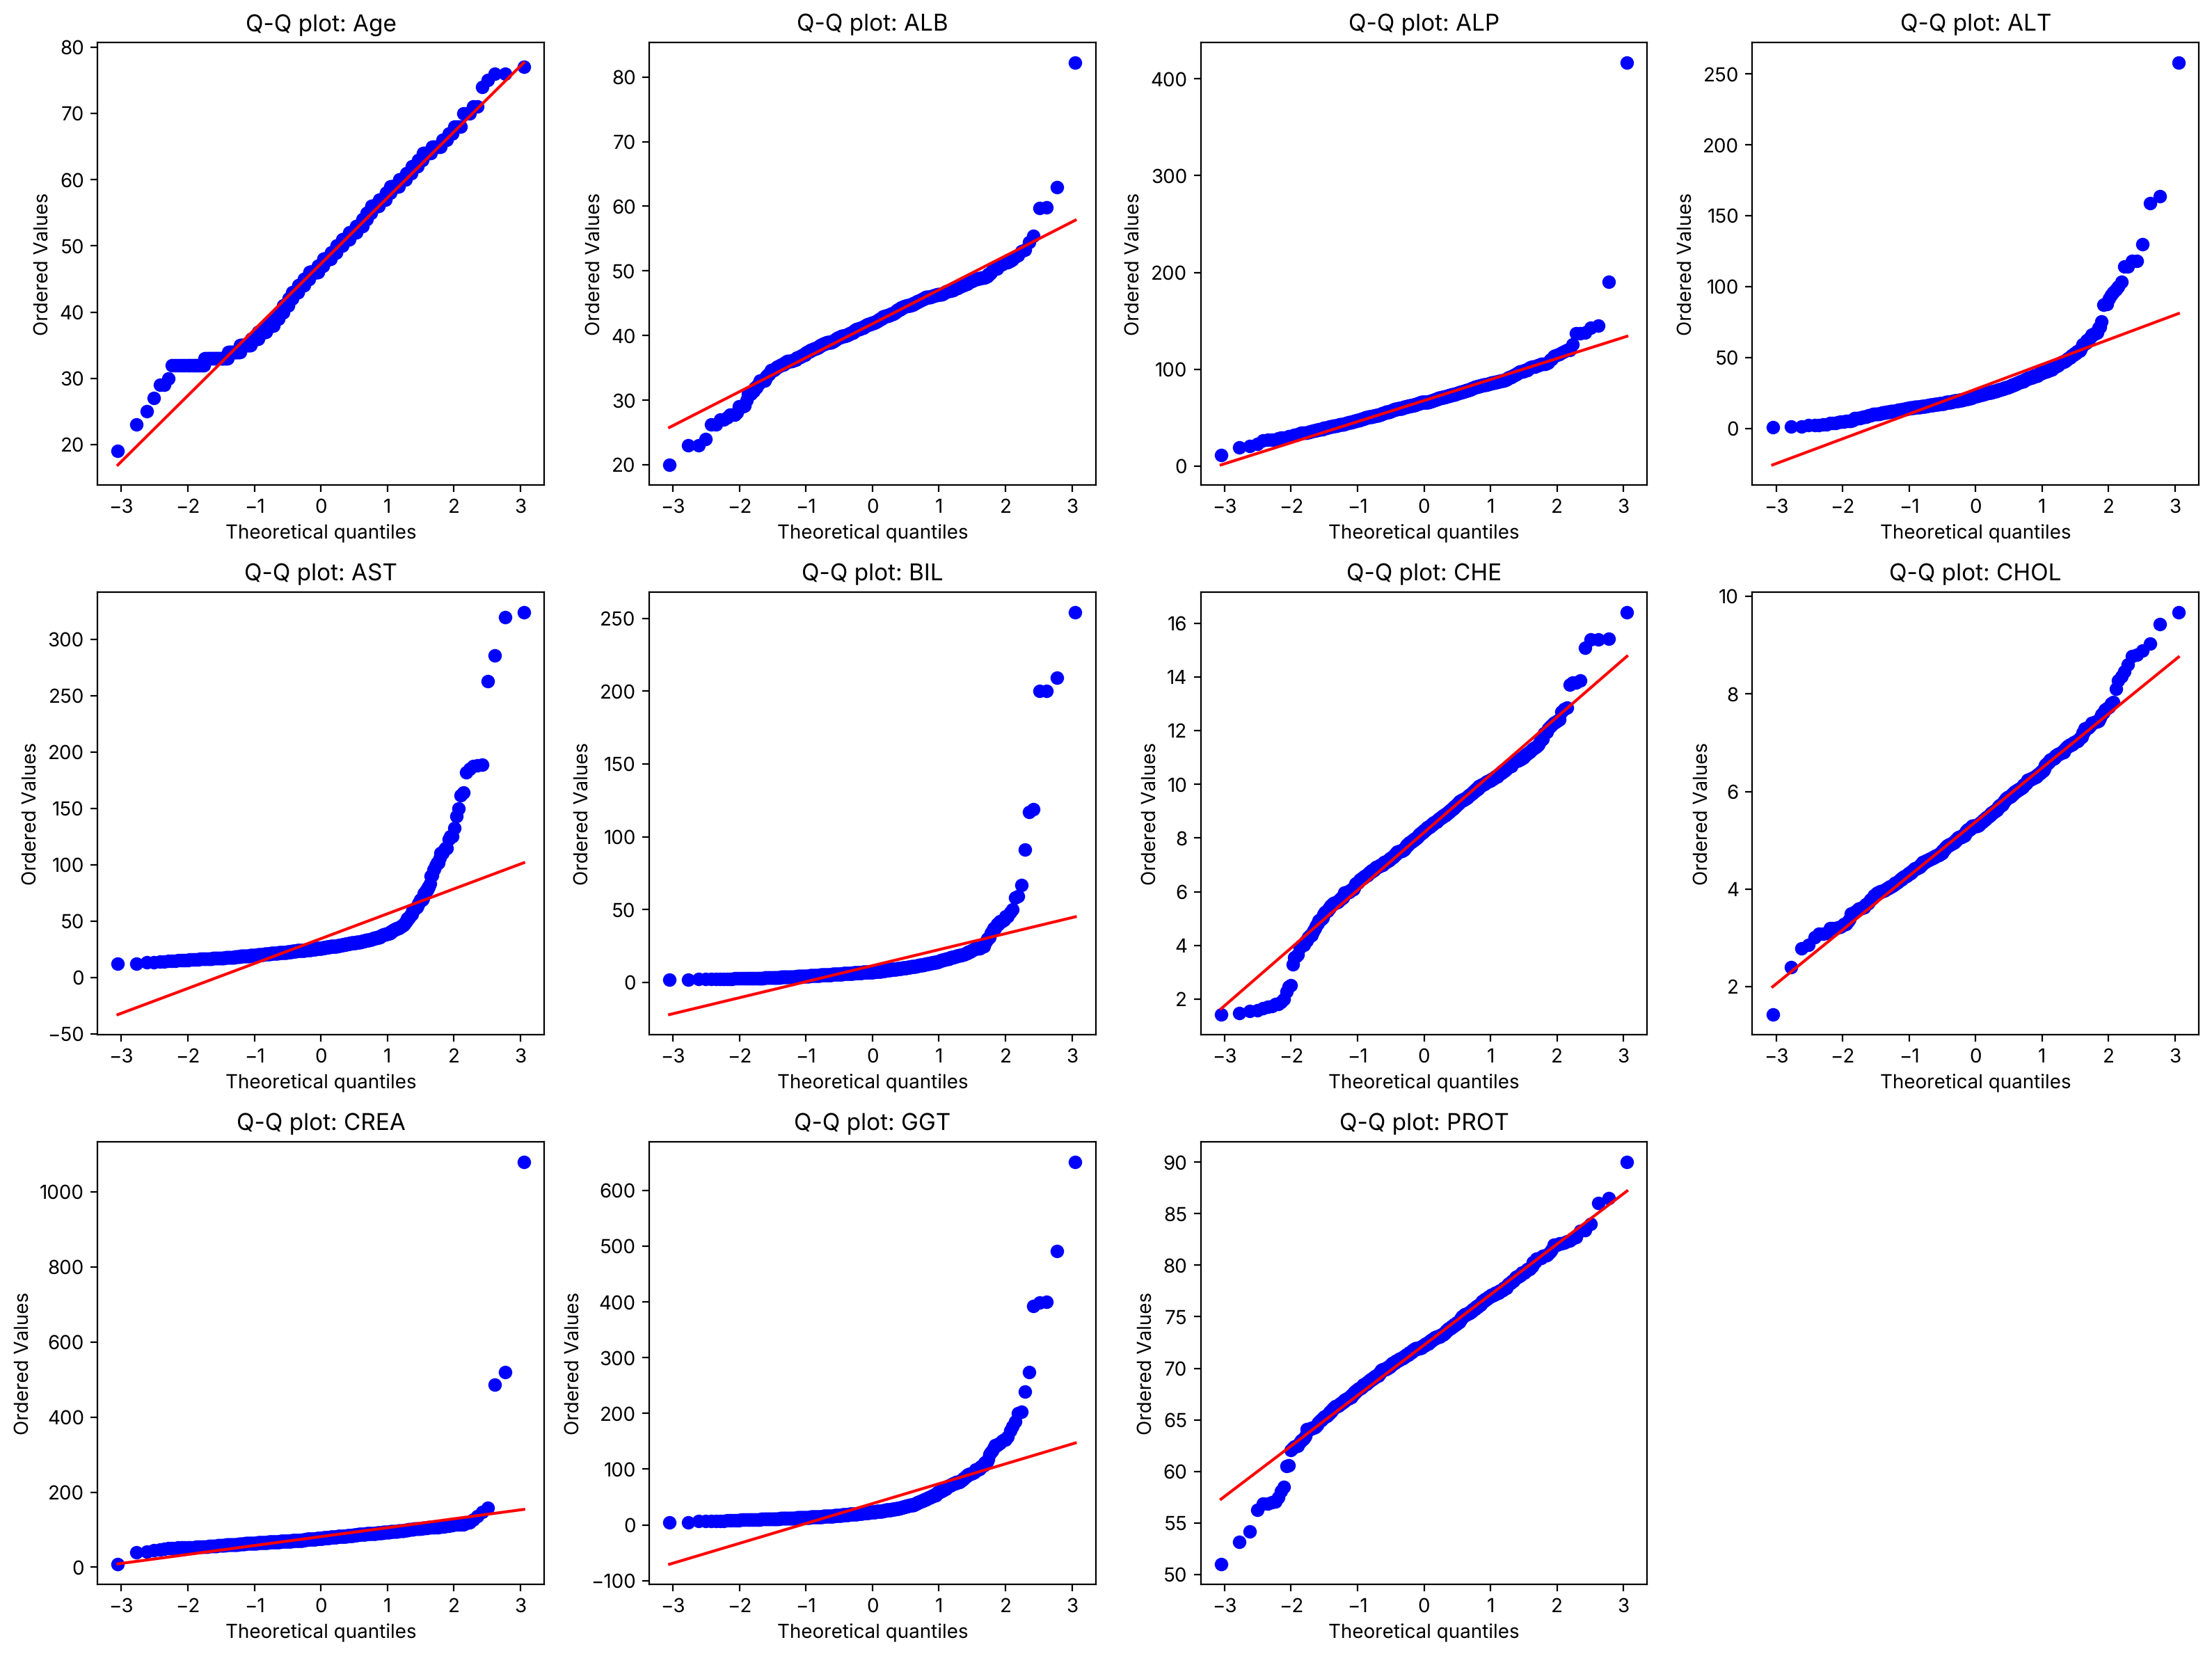

In [4]:
# lay the plots out in a grid with four per row
n_rows = int(np.ceil(len(NUMERIC_COLUMNS) / PLOTS_PER_ROW))
fig, axes = plt.subplots(
    n_rows, PLOTS_PER_ROW, figsize=(4 * PLOTS_PER_ROW, 4 * n_rows))
axes = axes.flatten()

# A Q-Q plot compares the data with a normal distribution; points close
# to the line mean the data look normal
for ax, column in zip(axes, NUMERIC_COLUMNS):
    stats.probplot(df[column], dist="norm", plot=ax)
    ax.set_title(f"Q-Q plot: {column}")

# remove the empty panels left in the last row
for ax in axes[len(NUMERIC_COLUMNS):]:
    fig.delaxes(ax)
fig.tight_layout()
plt.show()

### Findings

The Q-Q plots agree with the tests. AST, BIL, CREA, GGT, ALT and ALP bend sharply away from the line at the top, which shows a long right tail. Age, CHE, CHOL and PROT stay close to the line, but the tests still reject normality for them.

## Statistical testing

The variables are not normal, so the Kruskal-Wallis test is used first. The effect size is eta-squared, (H - k + 1) / (n - k): small below 0.06, medium below 0.14 and large from 0.14. The p-values are Bonferroni adjusted for 11 tests.

In [5]:
# number of patients, number of groups and the order of the groups
n = len(df)
k = len(CLASS_ORDER)

kruskal_rows = []
for column in NUMERIC_COLUMNS:
    # split the variable into one set of values per category
    groups = [df.loc[df[TARGET] == name, column] for name in CLASS_ORDER]

    # Kruskal-Wallis compares the ranks of the values across groups, so it
    # does not need the data to be normal
    h_stat, p_value = stats.kruskal(*groups)

    # effect size eta-squared based on H: how much of the variation is
    # explained by the category
    eta_squared = (h_stat - k + 1) / (n - k)

    # conventional labels for the size of the effect
    if eta_squared < 0.06:
        magnitude = "small"
    elif eta_squared < 0.14:
        magnitude = "medium"
    else:
        magnitude = "large"

    kruskal_rows.append({
        "Variable": column,
        "H": h_stat,
        "p": p_value,
        "eta2_H": eta_squared,
        "Magnitude": magnitude,
    })
kruskal_df = pd.DataFrame(kruskal_rows)

# Bonferroni: multiply by the 11 tests and cap at 1
kruskal_df["p (adj)"] = (
    kruskal_df["p"] * len(NUMERIC_COLUMNS)).clip(upper=1)
kruskal_df["Significant"] = kruskal_df["p (adj)"] < ALPHA

# show the strongest effects first
kruskal_df = kruskal_df.sort_values("eta2_H", ascending=False)
kruskal_df.set_index("Variable")

,H,p,eta2_H,Magnitude,p (adj),Significant
Variable,,,,,,
AST,158.142287,4.613425e-34,0.256858,large,5.074768e-33,True
GGT,106.328307,6.766970e-23,0.171073,large,7.443667e-22,True
BIL,93.648308,3.603991e-20,0.150080,large,3.964390e-19,True
CHE,67.088464,1.792767e-14,0.106107,medium,1.972043e-13,True
ALB,58.075653,1.514479e-12,0.091185,medium,1.665927e-11,True
CHOL,53.156349,1.697909e-11,0.083040,medium,1.867699e-10,True
ALP,46.093848,5.416796e-10,0.071347,medium,5.958476e-09,True
Age,29.465045,1.788107e-06,0.043816,small,1.966918e-05,True
ALT,21.859771,6.976358e-05,0.031225,small,7.673993e-04,True


### Findings

10 of the 11 variables differ between the four categories after adjustment. CREA is the exception (adjusted p 0.1828). The largest effects are AST (0.257), GGT (0.171) and BIL (0.150). CHE (0.106), ALB (0.091), CHOL (0.083) and ALP (0.071) are medium. Age (0.044), ALT (0.031), PROT (0.024) and CREA (0.012) are small. The test does not show which categories differ.

## One-way ANOVA after quantile transformation

The quantile transformation gives each variable a normal shape so that one-way ANOVA can be used as a second check. The transformer is fitted on all the data here because this is only for testing, not for modelling. Eta-squared is SS_between / SS_total and the p-values are Bonferroni adjusted for 11 tests.

In [6]:
# transform every variable so that it follows a normal distribution
# n_quantiles is capped at the sample size to avoid a sklearn warning
# the transformer is fitted on all the data; this is for exploration only
transformer = QuantileTransformer(
    n_quantiles=len(df), output_distribution="normal",
    random_state=SEED)
df_transformed = df.copy()
df_transformed[NUMERIC_COLUMNS] = transformer.fit_transform(
    df[NUMERIC_COLUMNS])

anova_rows = []
for column in NUMERIC_COLUMNS:
    # one set of transformed values per category
    groups = [
        df_transformed.loc[df_transformed[TARGET] == name, column]
        for name in CLASS_ORDER
    ]

    # One-way ANOVA tests whether the group means differ
    f_stat, p_value = stats.f_oneway(*groups)

    # effect size eta-squared: variation between group means divided by
    # the total variation (SS_between / SS_total)
    grand_mean = df_transformed[column].mean()
    ss_between = 0
    for group in groups:
        ss_between += len(group) * (group.mean() - grand_mean) ** 2
    ss_total = ((df_transformed[column] - grand_mean) ** 2).sum()

    anova_rows.append({
        "Variable": column,
        "F": f_stat,
        "p": p_value,
        "eta2": ss_between / ss_total,
    })
anova_df = pd.DataFrame(anova_rows)

# Bonferroni: multiply by the 11 tests and cap at 1
anova_df["p (adj)"] = anova_df["p"] * len(NUMERIC_COLUMNS)
anova_df["p (adj)"] = anova_df["p (adj)"].clip(upper=1)
anova_df["Significant"] = anova_df["p (adj)"] < ALPHA

# show the smallest p-values first
anova_df = anova_df.sort_values("p")
anova_df.set_index("Variable")

,F,p,eta2,p (adj),Significant
Variable,,,,,
AST,85.597383,3.680313e-46,0.298321,4.048344e-45,True
GGT,48.926355,2.570264e-28,0.195502,2.827290e-27,True
BIL,46.470542,4.948759e-27,0.187530,5.443635e-26,True
CHE,42.320376,7.822367e-25,0.173691,8.604604e-24,True
ALB,30.599431,1.999838e-18,0.131932,2.199822e-17,True
CHOL,23.417681,2.380066e-14,0.104194,2.618073e-13,True
ALP,21.611954,2.626788e-13,0.096938,2.889466e-12,True
ALT,15.390551,1.165335e-09,0.071015,1.281868e-08,True
Age,14.778126,2.690075e-09,0.068382,2.959083e-08,True


### Findings

The ANOVA agrees with Kruskal-Wallis. The same 10 variables are significant and CREA is not (adjusted p 0.9882). AST has the strongest effect (eta-squared 0.298), followed by GGT (0.196), BIL (0.188) and CHE (0.174). The differences between categories therefore show up in both a rank-based test and a parametric test. Equal variances were not checked.

## Correlation after transformation

Pearson correlation of the transformed variables, including the category code `cat_num` as in COM725.

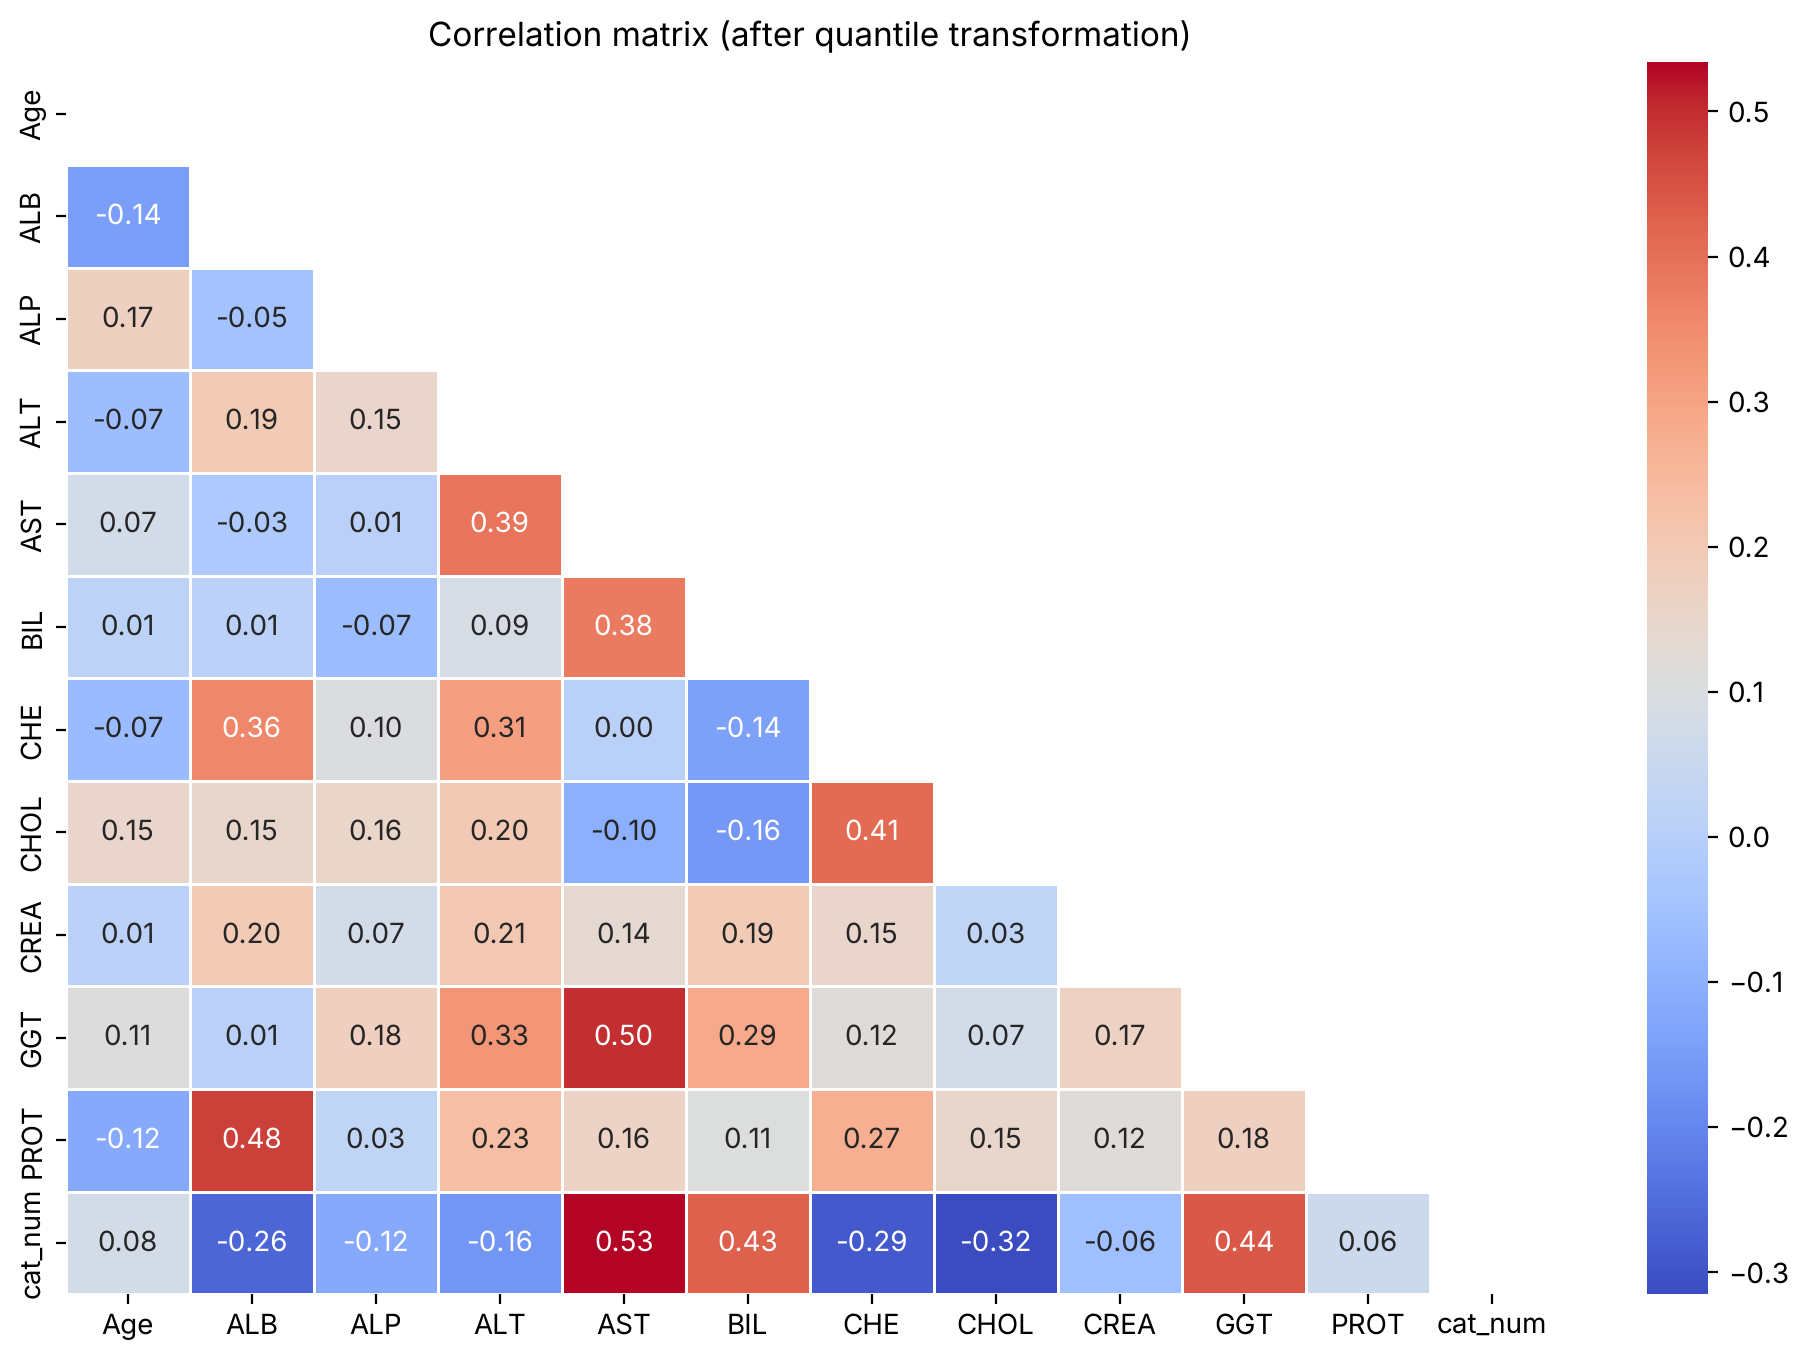

In [7]:
# Pearson correlation of the transformed variables, plus the category code
corr_matrix = df_transformed[NUMERIC_COLUMNS + ["cat_num"]].corr(
    method="pearson")

# hide the upper triangle, because the matrix is symmetric
upper_triangle = np.triu(np.ones_like(corr_matrix, dtype=bool))

# draw the heatmap with the value printed to 2 decimal places
plt.figure(figsize=(12, 8))
sns.heatmap(
    corr_matrix, mask=upper_triangle, annot=True, fmt=".2f",
    cmap="coolwarm", linewidths=0.5,
)
plt.title("Correlation matrix (after quantile transformation)")
plt.show()

### Findings

`cat_num` is most related to AST (0.53), GGT (0.44) and BIL (0.43), and negatively to CHOL (-0.32), CHE (-0.29) and ALB (-0.26). Age, PROT and CREA are close to zero. The strongest pairs among the measurements are AST and GGT (0.50), ALB and PROT (0.48), CHE and CHOL (0.41) and ALT and AST (0.39).

## Differences by sex

Each measurement is compared between women and men with the Mann-Whitney U test, because none of them is normally distributed. The effect size is the rank-biserial correlation, r = 1 - 2U / (n1 x n2): 0 means no difference and values near -1 or 1 mean almost no overlap. The test is run in all 608 patients and again in the 533 healthy donors, since more of the sick patients are men. The p-values are Bonferroni adjusted for 11 tests in each group.

In [8]:
# Mann-Whitney U test for every measurement, women against men, first in
# all patients and then in the healthy donors only
groups = {
    "All patients": df,
    "Healthy donors only": df[df[TARGET] == "Healthy"],
}
for group_name, group in groups.items():
    rows = []
    for column in NUMERIC_COLUMNS:
        women = group.loc[group["Sex"] == "f", column]
        men = group.loc[group["Sex"] == "m", column]
        u_stat, p_value = stats.mannwhitneyu(
            women, men, alternative="two-sided"
        )
        rows.append({
            "Variable": column,
            "Median women": women.median(),
            "Median men": men.median(),
            "U": u_stat,
            # rank-biserial correlation as the effect size
            "r": 1 - 2 * u_stat / (len(women) * len(men)),
            "p": p_value,
        })
    result = pd.DataFrame(rows).set_index("Variable")

    # Bonferroni: multiply by the 11 tests and cap at 1
    result["p (adj)"] = (result["p"] * len(NUMERIC_COLUMNS)).clip(upper=1)
    result["Significant"] = result["p (adj)"] < ALPHA
    print(group_name)
    display(result.round(4))

All patients


,Median women,Median men,U,r,p,p (adj),Significant
Variable,,,,,,,
Age,48.00,46.00,46128.0,-0.0492,0.3054,1.0000,False
ALB,40.10,42.90,32353.5,0.2641,0.0000,0.0000,True
ALP,65.70,66.00,42721.0,0.0283,0.5566,1.0000,False
ALT,18.30,26.30,27454.5,0.3755,0.0000,0.0000,True
AST,22.80,28.00,27540.0,0.3736,0.0000,0.0000,True
BIL,6.10,8.60,29940.0,0.3190,0.0000,0.0000,True
CHE,7.68,8.63,33501.5,0.2380,0.0000,0.0000,True
CHOL,5.30,5.30,45438.5,-0.0336,0.4852,1.0000,False
CREA,68.00,83.00,17216.5,0.6084,0.0000,0.0000,True


Healthy donors only


,Median women,Median men,U,r,p,p (adj),Significant
Variable,,,,,,,
Age,48.00,46.00,34944.5,-0.0222,0.6633,1.0000,False
ALB,40.50,43.20,24539.0,0.2822,0.0000,0.0000,True
ALP,65.70,67.70,32245.0,0.0568,0.2662,1.0000,False
ALT,18.40,27.10,18575.0,0.4566,0.0000,0.0000,True
AST,22.10,26.90,20379.5,0.4038,0.0000,0.0000,True
BIL,5.80,7.60,22992.0,0.3274,0.0000,0.0000,True
CHE,7.84,8.70,24992.0,0.2689,0.0000,0.0000,True
CHOL,5.38,5.38,34428.0,-0.0071,0.8894,1.0000,False
CREA,68.00,85.00,10508.5,0.6926,0.0000,0.0000,True


### Findings

In all 608 patients, 7 of the 11 measurements differ between women and men after Bonferroni correction: ALB, ALT, AST, BIL, CHE, CREA and GGT. In the 533 healthy donors alone the same 7 differ, and PROT joins them (adjusted p = 0.042), so sex differences exist even without disease. Disease may still add to them in the full sample, as 71% of the sick patients are men against 60% of the donors. The largest effect is CREA (r = 0.69 in healthy donors), followed by ALT (0.46), AST (0.40) and GGT (0.38), all higher in men. Age, ALP and CHOL do not differ. Sex is therefore kept as a predictor, and model performance is reported for men and women separately.

## Sample size

The dataset is fixed, so this section checks whether it is large enough to develop each model without overfitting, using the criteria of Riley et al. (2020) for the binary outcome and Pate et al. (2023) for the multinomial outcomes. The criteria are built for regression models, so for random forest and decision tree they are a guide only.

- **Criterion 1:** the model's coefficients should need little shrinkage (expected shrinkage of at least 0.9).
- **Criterion 2:** the apparent Nagelkerke R-squared should be at most 0.05 too optimistic.
- **Criterion 3:** the overall risk should be estimated within +/- 0.05.

All three need an expected Cox-Snell R-squared, which measures how much the predictors explain. There is no published model for this exact population to borrow it from, so the conservative default of Riley et al. (2020) is used: 15% of the largest value possible for the outcome's prevalence. The R-squared implied by AUROCs of 0.80 and 0.95 (Riley et al., 2022) is shown as a check. 13 predictor parameters are counted: age, sex, ten lab values and the AST/ALT ratio.

In [9]:
# libraries for the sample size calculation
import statsmodels.api as sm
from itertools import combinations
from scipy.stats import norm

# Riley et al. (2022): the Cox-Snell R-squared that goes with an expected
# AUROC. A large group of patients is simulated with a linear predictor
# that is normal in each class and gives that AUROC, and the R-squared is
# read off a logistic regression fitted to it. Prevalence: 75 of 608 sick
r2_from_auroc = {}
rng = np.random.default_rng(SEED)
for auroc in [0.80, 0.95]:
    y_sim = rng.random(1_000_000) < 75 / 608
    shift = np.sqrt(2) * norm.ppf(auroc)
    linear_predictor = rng.normal(np.where(y_sim, shift, 0.0), 1.0)
    fitted = sm.GLM(
        y_sim.astype(float), sm.add_constant(linear_predictor),
        family=sm.families.Binomial(),
    ).fit()
    null = sm.GLM(
        y_sim.astype(float), np.ones(len(y_sim)),
        family=sm.families.Binomial(),
    ).fit()
    r2_from_auroc[auroc] = 1 - np.exp(-2 * (fitted.llf - null.llf)
                                      / len(y_sim))
print({k: round(v, 3) for k, v in r2_from_auroc.items()})

{0.8: np.float64(0.131), 0.95: np.float64(0.337)}


### Healthy vs sick

In [10]:
# healthy vs sick: 75 sick patients among 608, 13 predictor parameters.
# Largest possible Cox-Snell R-squared for this prevalence
prevalence = 75 / 608
log_l_null = (prevalence * np.log(prevalence)
              + (1 - prevalence) * np.log(1 - prevalence))
max_r2 = 1 - np.exp(2 * log_l_null)

# no published model exists for this population, so the conservative
# default of Riley et al. (2020) is used (Nagelkerke R-squared of 0.15,
# i.e. 15% of the largest possible Cox-Snell R-squared). The values
# implied by AUROCs of 0.80 and 0.95 are shown as a check
scenarios = {
    "Conservative default (Nagelkerke 0.15)": 0.15 * max_r2,
    "Expected AUROC 0.80": r2_from_auroc[0.80],
    "Expected AUROC 0.95": r2_from_auroc[0.95],
}
rows = []
for scenario, r2 in scenarios.items():
    # criterion 1: expected shrinkage of at least 0.9
    n1 = 13 / ((0.9 - 1) * np.log(1 - r2 / 0.9))
    # criterion 2: apparent Nagelkerke R-squared at most 0.05 optimistic
    shrinkage = r2 / (r2 + 0.05 * max_r2)
    n2 = 13 / ((shrinkage - 1) * np.log(1 - r2 / shrinkage))
    # criterion 3: overall risk estimated within +/- 0.05
    n3 = (norm.ppf(0.975) / 0.05) ** 2 * prevalence * (1 - prevalence)
    required = int(np.ceil(max(n1, n2, n3)))
    rows.append({
        "Scenario": scenario, "Cox-Snell R2": r2,
        "Criterion 1": n1, "Criterion 2": n2, "Criterion 3": n3,
        "Required n": required,
        "Required sick patients": int(np.ceil(required * prevalence)),
        "Events per predictor needed": required * prevalence / 13,
    })
print("Available: 608 patients, 75 sick, "
      f"{75 / 13:.1f} sick patients per predictor parameter")
pd.DataFrame(rows).set_index("Scenario").round(3)

Available: 608 patients, 75 sick, 5.8 sick patients per predictor parameter


,Cox-Snell R2,Criterion 1,Criterion 2,Criterion 3,Required n,Required sick patients,Events per predictor needed
Scenario,,,,,,,
Conservative default (Nagelkerke 0.15),0.079,1416.139,467.563,166.164,1417,175,13.446
Expected AUROC 0.80,0.131,823.305,453.956,166.164,824,102,7.819
Expected AUROC 0.95,0.337,277.152,397.577,166.164,398,50,3.777


### Four classes and three disease stages

In [11]:
# multinomial outcomes (Pate et al., 2023). A multinomial model is a set
# of logistic submodels, one for each pair of categories. Criterion 1 is
# applied to every pair, and the pair's required size is scaled up by the
# share of all patients that belong to that pair. Criterion 3 asks for
# each category's risk within +/- 0.05. The same conservative R-squared
# default is used for each pair (Nagelkerke 0.15), with 13 parameters
multiclass_outcomes = {
    "Four classes": {"Healthy": 533, "Hepatitis": 24, "Fibrosis": 21,
                     "Cirrhosis": 30},
    "Three disease stages": {"Hepatitis": 24, "Fibrosis": 21,
                             "Cirrhosis": 30},
}
for outcome_name, counts in multiclass_outcomes.items():
    total = sum(counts.values())
    rows = []
    for first, second in combinations(counts, 2):
        n_pair = counts[first] + counts[second]
        pair_prevalence = counts[second] / n_pair
        log_l_null = (pair_prevalence * np.log(pair_prevalence)
                      + (1 - pair_prevalence) * np.log(1 - pair_prevalence))
        r2 = 0.15 * (1 - np.exp(2 * log_l_null))
        n1 = 13 / ((0.9 - 1) * np.log(1 - r2 / 0.9))
        rows.append({
            "Pair": f"{first} vs {second}", "Patients in pair": n_pair,
            "Required in pair": int(np.ceil(n1)),
            "Required in total": int(np.ceil(n1 * total / n_pair)),
        })
    for class_name, n_class in counts.items():
        share = n_class / total
        rows.append({
            "Pair": f"Risk of {class_name} (criterion 3)",
            "Patients in pair": total, "Required in pair": None,
            "Required in total": int(np.ceil(
                (norm.ppf(0.975) / 0.05) ** 2 * share * (1 - share))),
        })
    table = pd.DataFrame(rows).set_index("Pair")
    print(f"{outcome_name}: available {total}, "
          f"required {table['Required in total'].max()}")
    display(table)

Four classes: available 608, required 13175


,Patients in pair,Required in pair,Required in total
Pair,,,
Healthy vs Hepatitis,557,2543.0,2776
Healthy vs Fibrosis,554,2765.0,3034
Healthy vs Cirrhosis,563,2226.0,2404
Hepatitis vs Fibrosis,45,976.0,13175
Hepatitis vs Cirrhosis,54,978.0,11011
Fibrosis vs Cirrhosis,51,985.0,11740
Risk of Healthy (criterion 3),608,NaN,167
Risk of Hepatitis (criterion 3),608,NaN,59
Risk of Fibrosis (criterion 3),608,NaN,52


Three disease stages: available 75, required 1626


,Patients in pair,Required in pair,Required in total
Pair,,,
Hepatitis vs Fibrosis,45,976.0,1626
Hepatitis vs Cirrhosis,54,978.0,1359
Fibrosis vs Cirrhosis,51,985.0,1449
Risk of Hepatitis (criterion 3),75,NaN,335
Risk of Fibrosis (criterion 3),75,NaN,310
Risk of Cirrhosis (criterion 3),75,NaN,369


### Findings: sample size

**Healthy vs sick.** With the conservative default, 1,417 patients (175 sick) would be needed, against 608 (75 sick) available. The data are only large enough if the predictors explain the outcome very well: at an expected AUROC of 0.95, 398 patients (50 sick) would be enough. The primary analysis gives AUROCs close to that level, so the binary model is borderline adequate, and shrinkage should still be checked through the calibration slope.

**Four classes and three disease stages.** The data are far too small. Separating hepatitis from fibrosis alone would need about 976 patients from those two groups, and only 45 exist. Under the same assumptions the four-class model would need about 13,000 patients and the three-stage model about 1,600, against 608 and 75. Any multiclass result here is exploratory and likely to be overfitted, which matches the low fibrosis and hepatitis recall seen in every model.

## Summary

None of the 11 variables is normally distributed. 10 of the 11 differ between Healthy, Hepatitis, Fibrosis and Cirrhosis in both the Kruskal-Wallis test and the ANOVA. AST, GGT and BIL separate the categories most strongly. CREA is the only variable with no significant difference.

Women and men differ in 7 of the 11 measurements in all patients and 8 of 11 among healthy donors, with higher liver enzymes and creatinine in men.

The sample is borderline for healthy vs sick and far too small for naming the disease stage (Riley et al., 2020; Pate et al., 2023).